In [9]:
import pandas as pd
import re
import nltk
from nltk.tokenize import word_tokenize

# Load dataset
from google.colab import files
import pandas as pd

uploaded = files.upload()

df = pd.read_csv("Tweets.csv")

print("Dataset loaded successfully!")
print(df.head())
# Download tokenizer
nltk.download('punkt')
nltk.download('punkt_tab')

# Show sample tweets
print("Original Tweets:")
print(df['text'].head(10))

# Naive Tokenization
print("\nNAIVE TOKENIZATION")

for tweet in df['text'].head(5):
    print("\nOriginal:", tweet)
    print("Tokens:", word_tokenize(tweet))


# Improved Twitter Tokenization
def twitter_tokenizer(text):

    text = text.lower()

    # Replace URLs
    text = re.sub(r'https?://\S+|www\.\S+', ' URL ', text)

    # Replace usernames
    text = re.sub(r'@\w+', ' USER ', text)

    # Keep hashtag words but remove #
    text = re.sub(r'#(\w+)', r'\1', text)

    # Normalize stretched words
    text = re.sub(r'(.)\1{2,}', r'\1\1', text)

    # Extract words, emojis and punctuation
    tokens = re.findall(
        r'[\U0001F300-\U0001FAFF]|[a-zA-Z]+|\d+|[^\w\s]',
        text
    )

    return tokens


print("\nIMPROVED TWITTER TOKENIZATION")

for tweet in df['text'].head(5):
    print("\nOriginal:", tweet)
    print("Tokens:", twitter_tokenizer(tweet))

Saving Tweets.csv to Tweets (1).csv
Dataset loaded successfully!
             tweet_id airline_sentiment  airline_sentiment_confidence  \
0  570306133677760513           neutral                        1.0000   
1  570301130888122368          positive                        0.3486   
2  570301083672813571           neutral                        0.6837   
3  570301031407624196          negative                        1.0000   
4  570300817074462722          negative                        1.0000   

  negativereason  negativereason_confidence         airline  \
0            NaN                        NaN  Virgin America   
1            NaN                     0.0000  Virgin America   
2            NaN                        NaN  Virgin America   
3     Bad Flight                     0.7033  Virgin America   
4     Can't Tell                     1.0000  Virgin America   

  airline_sentiment_gold        name negativereason_gold  retweet_count  \
0                    NaN     cairdin      

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [11]:

#part A 2
import pandas as pd
import nltk
import re
from nltk.corpus import stopwords
from nltk.sentiment import SentimentIntensityAnalyzer
from IPython.display import display

# Download required NLTK resources
nltk.download('stopwords')
nltk.download('vader_lexicon')

# Load dataset if it has not already been loaded
if 'df' not in globals():
    df = pd.read_csv("Tweets.csv")

# Find the tweet text column
text_column = 'text' if 'text' in df.columns else 'tweet'

# Prepare stopwords
standard_stopwords = set(stopwords.words('english'))

# Words that should NOT be removed
negation_words = {'not', 'no', 'nor'}

# Final stopword list keeps negation words
final_stopwords = standard_stopwords - negation_words

# Function to remove stopwords
def remove_stopwords(text, stop_words):
    words = re.findall(r"\b\w+\b", str(text).lower())
    return " ".join(word for word in words if word not in stop_words)

# Apply both cleaning methods
df['without_negations'] = df[text_column].apply(
    lambda x: remove_stopwords(x, standard_stopwords)
)

df['with_negations'] = df[text_column].apply(
    lambda x: remove_stopwords(x, final_stopwords)
)

# Initialize sentiment analyzer
sia = SentimentIntensityAnalyzer()

# Calculate sentiment scores
df['original_sentiment'] = df[text_column].apply(
    lambda x: sia.polarity_scores(str(x))['compound']
)

df['sentiment_without_negations'] = df['without_negations'].apply(
    lambda x: sia.polarity_scores(x)['compound']
)

df['sentiment_with_negations'] = df['with_negations'].apply(
    lambda x: sia.polarity_scores(x)['compound']
)

# Convert scores into sentiment labels
def sentiment_label(score):
    if score >= 0.05:
        return 'Positive'
    elif score <= -0.05:
        return 'Negative'
    else:
        return 'Neutral'

df['label_without_negations'] = df['sentiment_without_negations'].apply(sentiment_label)
df['label_with_negations'] = df['sentiment_with_negations'].apply(sentiment_label)

# Display examples where sentiment changes
changed = df[
    df['label_without_negations'] != df['label_with_negations']
]

print("Examples where removing negation words changes sentiment:")
display(changed[[text_column, 'without_negations', 'with_negations',
                 'label_without_negations', 'label_with_negations']].head(10))

# Compare overall sentiment results
comparison = pd.DataFrame({
    'Method': ['Negations Removed', 'Negations Kept'],
    'Positive': [
        (df['label_without_negations'] == 'Positive').sum(),
        (df['label_with_negations'] == 'Positive').sum()
    ],
    'Negative': [
        (df['label_without_negations'] == 'Negative').sum(),
        (df['label_with_negations'] == 'Negative').sum()
    ],
    'Neutral': [
        (df['label_without_negations'] == 'Neutral').sum(),
        (df['label_with_negations'] == 'Neutral').sum()
    ]
})

print("\nOverall sentiment comparison:")
display(comparison)

print("\nNumber of tweets whose sentiment changed:",
      len(changed))

# Demonstrate the effect with simple examples
examples = [
    "I am happy with this airline",
    "I am not happy with this airline",
    "The flight was good",
    "The flight was not good"
]

print("\nSimple examples:")
for tweet in examples:
    removed = remove_stopwords(tweet, standard_stopwords)
    kept = remove_stopwords(tweet, final_stopwords)

    print("\nOriginal:", tweet)
    print("Negations removed:", removed)
    print("Negations kept:", kept)
    print("Sentiment after removing negations:",
          sentiment_label(sia.polarity_scores(removed)['compound']))
    print("Sentiment after keeping negations:",
          sentiment_label(sia.polarity_scores(kept)['compound']))

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package vader_lexicon to /root/nltk_data...


Examples where removing negation words changes sentiment:


,text,without_negations,with_negations,label_without_negations,label_with_negations
25,@VirginAmerica status match program. I applie...,virginamerica status match program applied thr...,virginamerica status match program applied thr...,Neutral,Negative
50,@VirginAmerica Is flight 769 on it's way? Was ...,virginamerica flight 769 way supposed take 30 ...,virginamerica flight 769 way supposed take 30 ...,Positive,Negative
65,@VirginAmerica Flight 0736 DAL to DCA 2/24 2:1...,virginamerica flight 0736 dal dca 2 24 2 10pm ...,virginamerica flight 0736 dal dca 2 24 2 10pm ...,Positive,Negative
74,"@VirginAmerica not worried, it's been a great ...",virginamerica worried great ride new plane gre...,virginamerica not worried great ride new plane...,Positive,Negative
83,@VirginAmerica I have no interesting flying wi...,virginamerica interesting flying cancelled fli...,virginamerica no interesting flying cancelled ...,Positive,Negative
93,"@VirginAmerica just landed in LAX, an hour aft...",virginamerica landed lax hour late flight bag ...,virginamerica landed lax hour no late flight b...,Positive,Negative
145,@VirginAmerica I paid the premium to fly you a...,virginamerica paid premium fly across country ...,virginamerica paid premium fly across country ...,Neutral,Negative
146,@VirginAmerica question: is it not possible to...,virginamerica question possible book seat infa...,virginamerica question not possible book seat ...,Positive,Negative
164,@VirginAmerica - Your site seems a little wonk...,virginamerica site seems little wonked right m...,virginamerica site seems little wonked right m...,Positive,Negative
180,@VirginAmerica can you please have flights in ...,virginamerica please flights sjc choice fly so...,virginamerica please flights sjc no choice fly...,Positive,Neutral



Overall sentiment comparison:


,Method,Positive,Negative,Neutral
0,Negations Removed,8057,3709,2874
1,Negations Kept,7754,4244,2642



Number of tweets whose sentiment changed: 863

Simple examples:

Original: I am happy with this airline
Negations removed: happy airline
Negations kept: happy airline
Sentiment after removing negations: Positive
Sentiment after keeping negations: Positive

Original: I am not happy with this airline
Negations removed: happy airline
Negations kept: not happy airline
Sentiment after removing negations: Positive
Sentiment after keeping negations: Negative

Original: The flight was good
Negations removed: flight good
Negations kept: flight good
Sentiment after removing negations: Positive
Sentiment after keeping negations: Positive

Original: The flight was not good
Negations removed: flight good
Negations kept: flight not good
Sentiment after removing negations: Positive
Sentiment after keeping negations: Negative


In [12]:
# 3
import pandas as pd
import nltk
import re
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize

# Download required NLTK resources
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('wordnet')
nltk.download('omw-1.4')

# Load dataset if it has not already been loaded
if 'df' not in globals():
    df = pd.read_csv("Tweets.csv")

# Find tweet text column
text_column = 'text' if 'text' in df.columns else 'tweet'

# Initialize stemming and lemmatization tools
stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

# Get all words from tweets
all_words = []

for tweet in df[text_column].dropna():
    words = re.findall(r"\b[a-zA-Z]+\b", str(tweet).lower())
    all_words.extend(words)

# Create original vocabulary
original_vocab = sorted(set(all_words))

# Apply stemming and lemmatization
stemmed_vocab = sorted(set(stemmer.stem(word) for word in original_vocab))
lemmatized_vocab = sorted(set(lemmatizer.lemmatize(word) for word in original_vocab))

# Compare the same sample vocabulary
sample_words = [
    'flights', 'flying', 'flies', 'delayed',
    'running', 'better', 'services', 'airlines',
    'cancelled', 'amazing', 'happiness', 'studies'
]

comparison = pd.DataFrame({
    'Original Word': sample_words,
    'Stemmed Word': [stemmer.stem(word) for word in sample_words],
    'Lemmatized Word': [lemmatizer.lemmatize(word) for word in sample_words]
})

print("Comparison of stemming and lemmatization:")
display(comparison)

# Find words where the two methods disagree
disagreements = pd.DataFrame({
    'Original Word': original_vocab,
    'Stemmed Word': [stemmer.stem(word) for word in original_vocab],
    'Lemmatized Word': [lemmatizer.lemmatize(word) for word in original_vocab]
})

disagreements = disagreements[
    disagreements['Stemmed Word'] != disagreements['Lemmatized Word']
]

print("\nWords where stemming and lemmatization disagree:")
display(disagreements.head(30))

# Compare vocabulary sizes
vocab_results = pd.DataFrame({
    'Processing Method': [
        'Original Vocabulary',
        'After Stemming',
        'After Lemmatization'
    ],
    'Vocabulary Size': [
        len(original_vocab),
        len(stemmed_vocab),
        len(lemmatized_vocab)
    ]
})

print("\nVocabulary size comparison:")
display(vocab_results)

# Calculate vocabulary reduction
print("\nVocabulary reduction:")
print("Stemming:",
      len(original_vocab) - len(stemmed_vocab), "words removed")

print("Lemmatization:",
      len(original_vocab) - len(lemmatized_vocab), "words removed")

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


Comparison of stemming and lemmatization:


,Original Word,Stemmed Word,Lemmatized Word
0,flights,flight,flight
1,flying,fli,flying
2,flies,fli,fly
3,delayed,delay,delayed
4,running,run,running
5,better,better,better
6,services,servic,service
7,airlines,airlin,airline
8,cancelled,cancel,cancelled
9,amazing,amaz,amazing



Words where stemming and lemmatization disagree:


,Original Word,Stemmed Word,Lemmatized Word
3,aaadvantage,aaadvantag,aaadvantage
4,aaalwayslate,aaalwaysl,aaalwayslate
5,aacustomerservice,aacustomerservic,aacustomerservice
6,aadavantage,aadavantag,aadavantage
9,aadvantage,aadvantag,aadvantage
18,abandoned,abandon,abandoned
19,abandonment,abandon,abandonment
21,abbreve,abbrev,abbreve
23,abcletjetbluestreamfeed,abcletjetbluestreamfe,abcletjetbluestreamfeed
25,abcnews,abcnew,abcnews



Vocabulary size comparison:


,Processing Method,Vocabulary Size
0,Original Vocabulary,11819
1,After Stemming,9134
2,After Lemmatization,10908



Vocabulary reduction:
Stemming: 2685 words removed
Lemmatization: 911 words removed


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


Information loss at each cleaning stage:


,Cleaning Stage,Vocabulary Size,Average Tweet Length,Empty Tweets
0,Original,30105,17.65,0
1,Lowercase,26840,17.65,0
2,Remove URLs,25663,17.57,0
3,Remove Mentions,24685,16.49,0
4,Remove Punctuation,15119,16.34,0
5,Remove Stopwords,14990,9.51,17
6,Lemmatization,14071,9.51,17


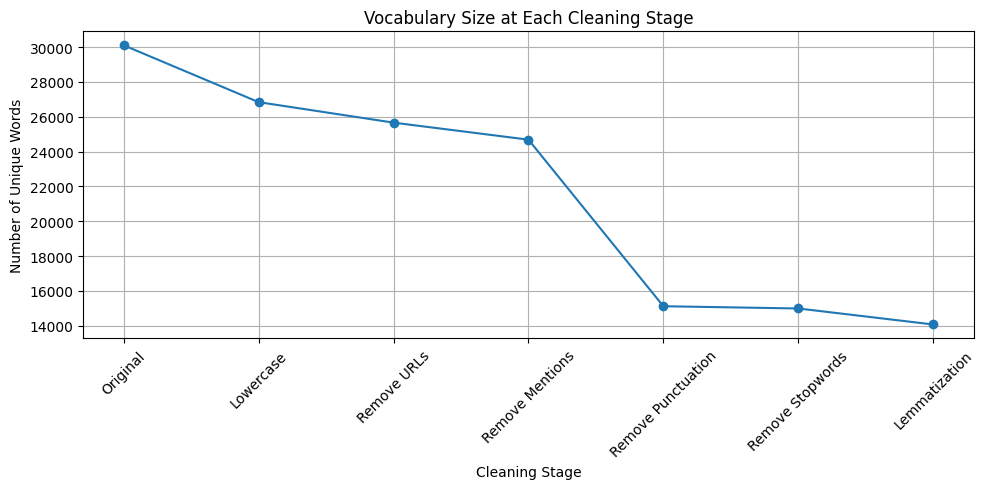

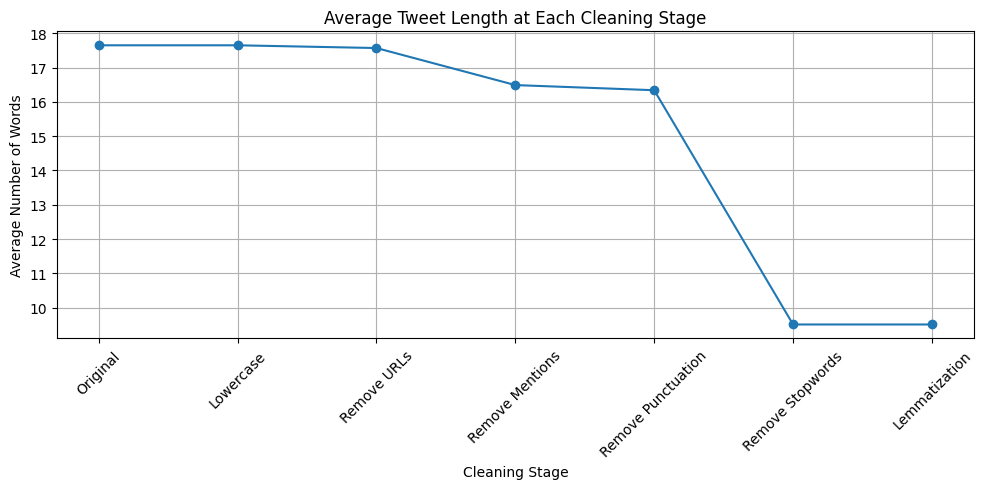

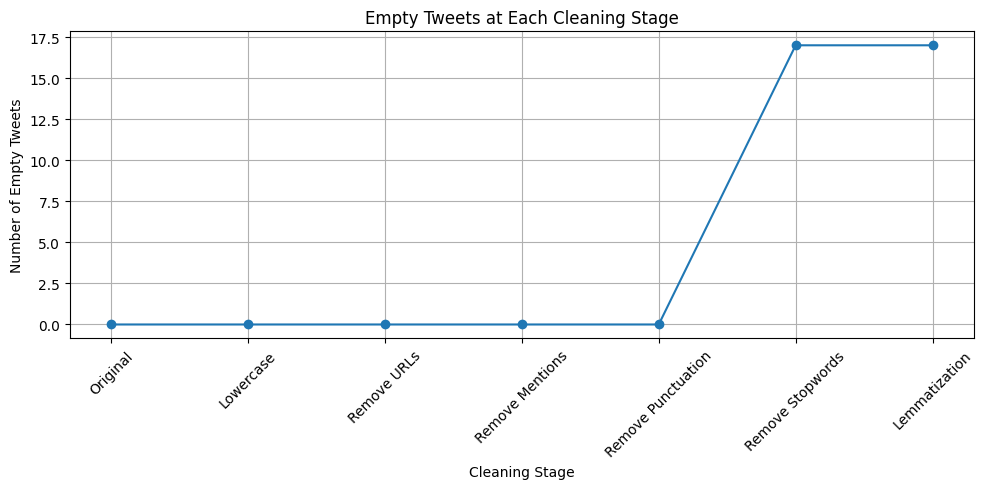

In [13]:
import pandas as pd
import re
import nltk
import string
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

# Download required NLTK resources
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('punkt')
nltk.download('punkt_tab')

# Load dataset if it has not already been loaded
if 'df' not in globals():
    df = pd.read_csv("Tweets.csv")

# Identify tweet text column
text_column = 'text' if 'text' in df.columns else 'tweet'

# Remove missing tweets
tweets = df[text_column].fillna('').astype(str)

# Prepare tools
stop_words = set(stopwords.words('english'))

# Keep negation words because they affect sentiment
stop_words = stop_words - {'not', 'no', 'nor'}

lemmatizer = WordNetLemmatizer()

# Cleaning functions
def remove_urls(text):
    return re.sub(r'http\S+|www\S+', '', text)

def remove_mentions(text):
    return re.sub(r'@\w+', '', text)

def remove_punctuation(text):
    return text.translate(str.maketrans('', '', string.punctuation))

def remove_stopwords(text):
    words = text.split()
    return ' '.join(word for word in words if word not in stop_words)

def apply_lemmatization(text):
    words = text.split()
    return ' '.join(lemmatizer.lemmatize(word) for word in words)

# Apply cleaning steps one by one
stages = {}

stages['Original'] = tweets
stages['Lowercase'] = stages['Original'].apply(lambda x: x.lower())
stages['Remove URLs'] = stages['Lowercase'].apply(remove_urls)
stages['Remove Mentions'] = stages['Remove URLs'].apply(remove_mentions)
stages['Remove Punctuation'] = stages['Remove Mentions'].apply(remove_punctuation)
stages['Remove Stopwords'] = stages['Remove Punctuation'].apply(remove_stopwords)
stages['Lemmatization'] = stages['Remove Stopwords'].apply(apply_lemmatization)

# Function to measure information loss
def calculate_metrics(series):
    token_lists = series.apply(lambda x: x.split())

    vocabulary = set(
        word for words in token_lists for word in words
    )

    return {
        'Vocabulary Size': len(vocabulary),
        'Average Tweet Length': round(token_lists.apply(len).mean(), 2),
        'Empty Tweets': (token_lists.apply(len) == 0).sum()
    }

# Calculate results for every cleaning stage
results = []

for stage, data in stages.items():
    metrics = calculate_metrics(data)
    metrics['Cleaning Stage'] = stage
    results.append(metrics)

results_df = pd.DataFrame(results)

# Display results
print("Information loss at each cleaning stage:")
display(results_df[
    ['Cleaning Stage', 'Vocabulary Size',
     'Average Tweet Length', 'Empty Tweets']
])

# Plot vocabulary size
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(results_df['Cleaning Stage'],
         results_df['Vocabulary Size'],
         marker='o')
plt.title('Vocabulary Size at Each Cleaning Stage')
plt.xlabel('Cleaning Stage')
plt.ylabel('Number of Unique Words')
plt.xticks(rotation=45)
plt.grid()
plt.tight_layout()
plt.show()

# Plot average tweet length
plt.figure(figsize=(10, 5))
plt.plot(results_df['Cleaning Stage'],
         results_df['Average Tweet Length'],
         marker='o')
plt.title('Average Tweet Length at Each Cleaning Stage')
plt.xlabel('Cleaning Stage')
plt.ylabel('Average Number of Words')
plt.xticks(rotation=45)
plt.grid()
plt.tight_layout()
plt.show()

# Plot empty tweets
plt.figure(figsize=(10, 5))
plt.plot(results_df['Cleaning Stage'],
         results_df['Empty Tweets'],
         marker='o')
plt.title('Empty Tweets at Each Cleaning Stage')
plt.xlabel('Cleaning Stage')
plt.ylabel('Number of Empty Tweets')
plt.xticks(rotation=45)
plt.grid()
plt.tight_layout()
plt.show()

In [14]:
#PARTb
#q5
import pandas as pd
import re
from collections import Counter
from IPython.display import display

# Load dataset if not already loaded
if 'df' not in globals():
    df = pd.read_csv("Tweets.csv")

# Identify tweet column
text_col = 'text' if 'text' in df.columns else 'tweet'

# Combine all tweets
tweets = df[text_col].fillna('').astype(str)

# Function to extract words
def get_words(text):
    return re.findall(r'\b[a-zA-Z]+\b', text.lower())

# 1. Most frequent words in raw data
raw_words = []
for tweet in tweets:
    raw_words.extend(get_words(tweet))

raw_frequency = Counter(raw_words)

print("Top 20 words in raw tweets:")
display(pd.DataFrame(raw_frequency.most_common(20),
                     columns=['Word', 'Frequency']))

# 2. Identify airline names from the dataset
airline_names = set()

if 'airline' in df.columns:
    for airline in df['airline'].dropna().unique():
        airline_names.update(get_words(str(airline)))

# 3. Generic filler words
generic_words = {
    'the', 'to', 'and', 'a', 'is', 'of', 'in', 'for',
    'on', 'my', 'it', 'i', 'you', 'me', 'we', 'our',
    'your', 'this', 'that', 'was', 'are', 'be', 'with',
    'at', 'have', 'had', 'do', 'so', 'but', 'just',
    'amp', 'get', 'got', 'will', 'would', 'can'
}

# Combine words to remove
unwanted_words = airline_names.union(generic_words)

# 4. Clean tweets
clean_words = []

for tweet in tweets:
    words = get_words(tweet)
    clean_words.extend([
        word for word in words if word not in unwanted_words
    ])

clean_frequency = Counter(clean_words)

print("\nTop 20 words after removing airline names and filler:")
display(pd.DataFrame(clean_frequency.most_common(20),
                     columns=['Word', 'Frequency']))

Top 20 words in raw tweets:


,Word,Frequency
0,to,8652
1,i,6703
2,the,6061
3,a,4514
4,you,4401
5,united,4164
6,for,3999
7,flight,3939
8,on,3815
9,and,3733



Top 20 words after removing airline names and filler:


,Word,Frequency
0,flight,3939
1,t,3350
2,usairways,3053
3,americanair,2964
4,southwestair,2461
5,jetblue,2395
6,not,1587
7,s,1556
8,no,1507
9,co,1214


In [15]:
#q6
import pandas as pd
import re
import math
from collections import Counter
from IPython.display import display

# Load dataset if needed
if 'df' not in globals():
    df = pd.read_csv("Tweets.csv")

text_col = 'text' if 'text' in df.columns else 'tweet'
sentiment_col = 'airline_sentiment'

# Select positive and negative tweets
positive_tweets = df[df[sentiment_col].str.lower() == 'positive'][text_col].fillna('')
negative_tweets = df[df[sentiment_col].str.lower() == 'negative'][text_col].fillna('')

# Words to exclude
stop_words = {
    'the', 'to', 'and', 'a', 'is', 'of', 'in', 'for',
    'on', 'my', 'it', 'i', 'you', 'me', 'we', 'our',
    'your', 'this', 'that', 'was', 'are', 'be', 'with',
    'at', 'have', 'had', 'do', 'so', 'but', 'just',
    'amp', 'get', 'got', 'will', 'would', 'can'
}

if 'airline' in df.columns:
    for airline in df['airline'].dropna().unique():
        stop_words.update(re.findall(r'\b[a-zA-Z]+\b', str(airline).lower()))

def extract_words(text):
    words = re.findall(r'\b[a-zA-Z]{2,}\b', str(text).lower())
    return [word for word in words if word not in stop_words]

# Count words in each group
positive_counts = Counter()
negative_counts = Counter()

for tweet in positive_tweets:
    positive_counts.update(extract_words(tweet))

for tweet in negative_tweets:
    negative_counts.update(extract_words(tweet))

# Total word counts
positive_total = sum(positive_counts.values())
negative_total = sum(negative_counts.values())

# Compare words appearing in both groups
all_words = set(positive_counts) | set(negative_counts)

results = []

for word in all_words:
    pos_count = positive_counts[word]
    neg_count = negative_counts[word]

    # Ignore very rare words
    if pos_count + neg_count < 10:
        continue

    pos_rate = pos_count / positive_total
    neg_rate = neg_count / negative_total

    # Positive score means more associated with positive tweets
    score = math.log((pos_rate + 1e-10) / (neg_rate + 1e-10))

    results.append({
        'Word': word,
        'Positive Count': pos_count,
        'Negative Count': neg_count,
        'Positive Rate': round(pos_rate, 6),
        'Negative Rate': round(neg_rate, 6),
        'Log Ratio': round(score, 3)
    })

comparison = pd.DataFrame(results)

print("Words most associated with positive tweets:")
display(comparison.sort_values('Log Ratio', ascending=False).head(15))

print("\nWords most associated with negative tweets:")
display(comparison.sort_values('Log Ratio').head(15))

Words most associated with positive tweets:


,Word,Positive Count,Negative Count,Positive Rate,Negative Rate,Log Ratio
428,imaginedragons,17,0,0.000790,0.000000,15.883
623,fortunemagazine,10,0,0.000465,0.000000,15.352
47,passbook,16,1,0.000744,0.000009,4.444
1319,favorite,14,1,0.000651,0.000009,4.310
1338,outstanding,12,1,0.000558,0.000009,4.156
796,beautiful,11,1,0.000511,0.000009,4.069
622,flyfi,10,1,0.000465,0.000009,3.974
408,fantastic,18,2,0.000837,0.000017,3.868
530,rock,27,3,0.001255,0.000026,3.868
415,kudos,26,3,0.001209,0.000026,3.831



Words most associated with negative tweets:


,Word,Positive Count,Negative Count,Positive Rate,Negative Rate,Log Ratio
86,worst,0,241,0.0,0.002107,-16.863
476,rude,0,134,0.0,0.001171,-16.276
436,fail,0,98,0.0,0.000857,-15.963
466,disappointed,0,97,0.0,0.000848,-15.953
1263,ridiculous,0,90,0.0,0.000787,-15.878
1479,unacceptable,0,89,0.0,0.000778,-15.867
883,paid,0,89,0.0,0.000778,-15.867
915,hung,0,86,0.0,0.000752,-15.833
1519,hr,0,69,0.0,0.000603,-15.612
1211,worse,0,63,0.0,0.000551,-15.521


In [16]:
#q7
import pandas as pd
import re
from collections import Counter
from nltk.sentiment import SentimentIntensityAnalyzer
import nltk
from IPython.display import display

# Download sentiment resource
nltk.download('vader_lexicon')

# Load dataset if needed
if 'df' not in globals():
    df = pd.read_csv("Tweets.csv")

text_col = 'text' if 'text' in df.columns else 'tweet'
sentiment_col = 'airline_sentiment'

# Select negative tweets
negative_tweets = df[
    df[sentiment_col].str.lower() == 'negative'
][text_col].fillna('').astype(str)

# Extract two-word phrases
bigrams = []

for tweet in negative_tweets:
    words = re.findall(r'\b[a-zA-Z]+\b', tweet.lower())

    for i in range(len(words) - 1):
        bigrams.append(words[i] + ' ' + words[i + 1])

# Count phrases
bigram_counts = Counter(bigrams)

print("Top 30 phrases in negative tweets:")
display(pd.DataFrame(
    bigram_counts.most_common(30),
    columns=['Phrase', 'Frequency']
))

# Show potentially useful operational phrases
operational_terms = [
    'flight', 'delay', 'delayed', 'cancelled', 'cancel',
    'customer', 'service', 'baggage', 'luggage',
    'boarding', 'seat', 'wait', 'hours', 'agent',
    'connection', 'lost'
]

operational_phrases = {
    phrase: count
    for phrase, count in bigram_counts.items()
    if any(term in phrase.split() for term in operational_terms)
}

print("\nPotential operational problem phrases:")
display(pd.DataFrame(
    Counter(operational_phrases).most_common(20),
    columns=['Phrase', 'Frequency']
))

# Demonstrate how a phrase can flip sentiment
sia = SentimentIntensityAnalyzer()

examples = [
    'good',
    'not good',
    'happy',
    'not happy',
    'great',
    'not great'
]

sentiment_results = []

for phrase in examples:
    score = sia.polarity_scores(phrase)['compound']

    sentiment_results.append({
        'Word or Phrase': phrase,
        'Sentiment Score': score
    })

print("\nSentiment of individual words and phrases:")
display(pd.DataFrame(sentiment_results))

[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


Top 30 phrases in negative tweets:


,Phrase,Frequency
0,i m,516
1,on hold,508
2,can t,453
3,t co,452
4,customer service,450
5,cancelled flightled,448
6,http t,437
7,on the,430
8,my flight,406
9,don t,387



Potential operational problem phrases:


,Phrase,Frequency
0,customer service,450
1,cancelled flightled,448
2,my flight,406
3,a flight,257
4,late flight,221
5,cancelled flighted,204
6,flight to,181
7,the flight,164
8,flight was,135
9,flight from,132



Sentiment of individual words and phrases:


,Word or Phrase,Sentiment Score
0,good,0.4404
1,not good,-0.3412
2,happy,0.5719
3,not happy,-0.4585
4,great,0.6249
5,not great,-0.5096


Top negative words:


,Word,Frequency
0,flight,2943
1,usairways,2375
2,americanair,2110
3,not,1357
4,no,1326
5,southwestair,1214
6,jetblue,1052
7,cancelled,926
8,now,833
9,an,781


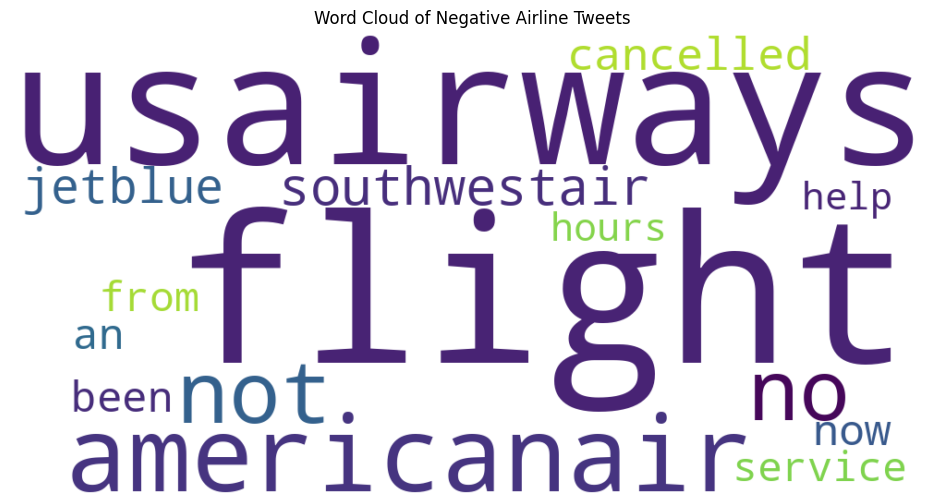

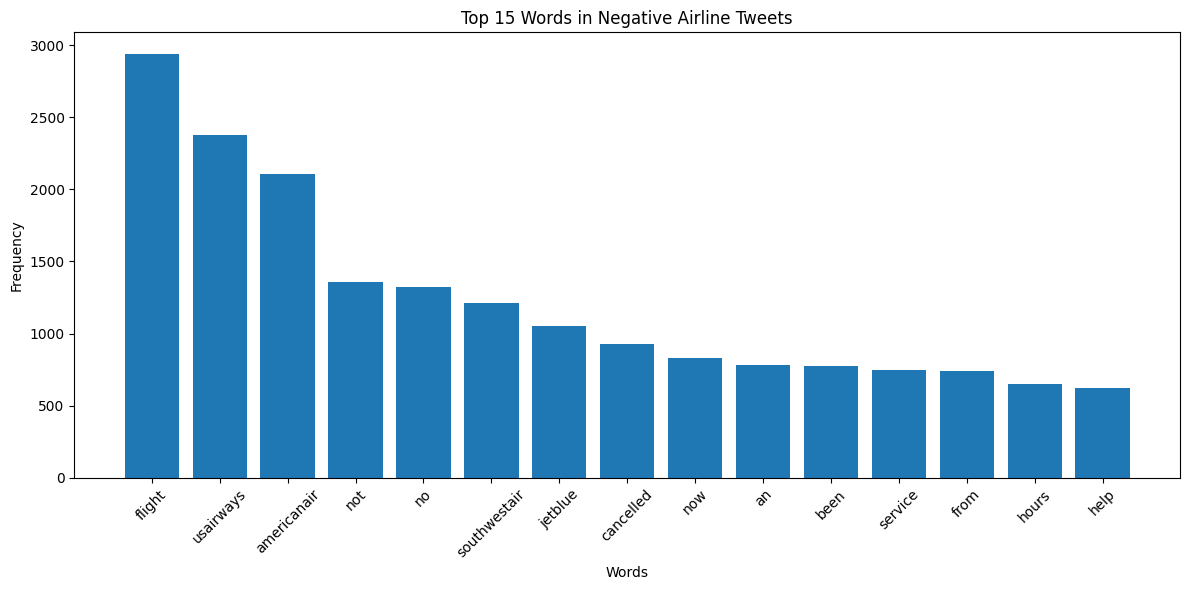

In [17]:
#q8
import pandas as pd
import re
from collections import Counter
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# If WordCloud is not installed, run this in a separate cell:
# !pip install wordcloud

# Load dataset if needed
if 'df' not in globals():
    df = pd.read_csv("Tweets.csv")

text_col = 'text' if 'text' in df.columns else 'tweet'
sentiment_col = 'airline_sentiment'

# Select negative tweets
negative_tweets = df[
    df[sentiment_col].str.lower() == 'negative'
][text_col].fillna('').astype(str)

# Remove generic filler and airline names
stop_words = {
    'the', 'to', 'and', 'a', 'is', 'of', 'in', 'for',
    'on', 'my', 'it', 'i', 'you', 'me', 'we', 'our',
    'your', 'this', 'that', 'was', 'are', 'be', 'with',
    'at', 'have', 'had', 'do', 'so', 'but', 'just',
    'amp', 'get', 'got', 'will', 'would', 'can'
}

if 'airline' in df.columns:
    for airline in df['airline'].dropna().unique():
        stop_words.update(
            re.findall(r'\b[a-zA-Z]+\b', str(airline).lower())
        )

# Count cleaned negative words
word_counts = Counter()

for tweet in negative_tweets:
    words = re.findall(r'\b[a-zA-Z]{2,}\b', tweet.lower())

    for word in words:
        if word not in stop_words:
            word_counts[word] += 1

# Select top 15 words
top_words = word_counts.most_common(15)

print("Top negative words:")
display(pd.DataFrame(top_words, columns=['Word', 'Frequency']))

# 1. Word cloud
wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color='white'
).generate_from_frequencies(dict(top_words))

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud of Negative Airline Tweets')
plt.show()

# 2. Bar chart using the SAME words and frequencies
words = [item[0] for item in top_words]
frequencies = [item[1] for item in top_words]

plt.figure(figsize=(12, 6))
plt.bar(words, frequencies)
plt.title('Top 15 Words in Negative Airline Tweets')
plt.xlabel('Words')
plt.ylabel('Frequency')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


Total tweets evaluated: 14640
Overall agreement (accuracy): 54.29 %

Classification report:
              precision    recall  f1-score   support

    positive       0.34      0.87      0.49      2363
    negative       0.90      0.50      0.64      9178
     neutral       0.38      0.43      0.41      3099

    accuracy                           0.54     14640
   macro avg       0.54      0.60      0.51     14640
weighted avg       0.70      0.54      0.57     14640



,VADER Negative,VADER Neutral,VADER Positive
Human Negative,2059,89,215
Human Neutral,2710,4564,1904
Human Positive,1343,431,1325


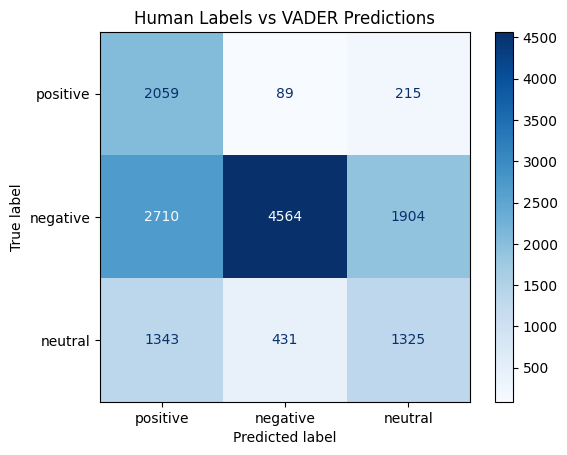

Recall by class: {'positive': 0.8713499788404571, 'negative': 0.4972760950098061, 'neutral': 0.4275572765408196}
Hardest class for VADER: neutral

Correctly classified examples:


,text,human_label,vader_label,vader_score
0,@VirginAmerica What @dhepburn said.,neutral,neutral,0.0000
2,@VirginAmerica I didn't today... Must mean I n...,neutral,neutral,0.0000
3,@VirginAmerica it's really aggressive to blast...,negative,negative,-0.5984
4,@VirginAmerica and it's a really big bad thing...,negative,negative,-0.5829
5,@VirginAmerica seriously would pay $30 a fligh...,negative,negative,-0.5945



Incorrectly classified examples:


,text,human_label,vader_label,vader_score
1,@VirginAmerica plus you've added commercials t...,positive,neutral,0.0000
7,@VirginAmerica Really missed a prime opportuni...,neutral,positive,0.1458
8,"@virginamerica Well, I didn't…but NOW I DO! :-D",positive,negative,-0.3477
10,@VirginAmerica did you know that suicide is th...,neutral,negative,-0.8555
13,@VirginAmerica @virginmedia I'm flying your #f...,positive,neutral,0.0000
16,@VirginAmerica So excited for my first cross c...,positive,negative,-0.5566
17,@VirginAmerica I flew from NYC to SFO last we...,negative,positive,0.5754
18,I ❤️ flying @VirginAmerica. ☺️👍,positive,neutral,0.0000
20,@VirginAmerica why are your first fares in May...,negative,neutral,0.0000
23,@VirginAmerica will you be making BOS&gt;LAS n...,neutral,negative,-0.2960


In [18]:
#part c
#q9
import pandas as pd
import re
import nltk
import matplotlib.pyplot as plt
from nltk.sentiment import SentimentIntensityAnalyzer
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

nltk.download('vader_lexicon')

# Load dataset if not already loaded
if 'df' not in globals():
    df = pd.read_csv("Tweets.csv")

# Find columns
columns = {c.lower(): c for c in df.columns}
text_col = columns.get('text', columns.get('tweet'))
label_col = columns.get(
    'airline_sentiment',
    columns.get('sentiment')
)

if text_col is None or label_col is None:
    raise ValueError("Could not find tweet text or sentiment label column. Check df.columns.")

# Keep rows with text and human labels
data = df.dropna(subset=[text_col, label_col]).copy()

# Standardize human labels
data['human_label'] = data[label_col].astype(str).str.lower().str.strip()

valid_labels = ['positive', 'negative', 'neutral']
data = data[data['human_label'].isin(valid_labels)].copy()

# Initialize VADER
sia = SentimentIntensityAnalyzer()

# Score each tweet
data['vader_score'] = data[text_col].apply(
    lambda x: sia.polarity_scores(str(x))['compound']
)

# Convert VADER scores into sentiment classes
def predict_sentiment(score):
    if score >= 0.05:
        return 'positive'
    elif score <= -0.05:
        return 'negative'
    else:
        return 'neutral'

data['vader_label'] = data['vader_score'].apply(predict_sentiment)

# Calculate agreement
accuracy = accuracy_score(
    data['human_label'],
    data['vader_label']
)

print("Total tweets evaluated:", len(data))
print("Overall agreement (accuracy):", round(accuracy * 100, 2), "%")

print("\nClassification report:")
print(classification_report(
    data['human_label'],
    data['vader_label'],
    labels=valid_labels,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(
    data['human_label'],
    data['vader_label'],
    labels=valid_labels
)

display(pd.DataFrame(
    cm,
    index=['Human Negative', 'Human Neutral', 'Human Positive'],
    columns=['VADER Negative', 'VADER Neutral', 'VADER Positive']
))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=valid_labels
).plot(cmap='Blues')

plt.title("Human Labels vs VADER Predictions")
plt.show()

# Find the hardest class using recall
report = classification_report(
    data['human_label'],
    data['vader_label'],
    labels=valid_labels,
    output_dict=True,
    zero_division=0
)

recalls = {
    label: report[label]['recall']
    for label in valid_labels
}

hardest_class = min(recalls, key=recalls.get)

print("Recall by class:", recalls)
print("Hardest class for VADER:", hardest_class)

# Show examples of correct and incorrect predictions
print("\nCorrectly classified examples:")
display(data[
    data['human_label'] == data['vader_label']
][[text_col, 'human_label', 'vader_label', 'vader_score']].head(5))

print("\nIncorrectly classified examples:")
display(data[
    data['human_label'] != data['vader_label']
][[text_col, 'human_label', 'vader_label', 'vader_score']].head(10))

In [19]:
#q10
import pandas as pd
import re
import nltk
from nltk.sentiment import SentimentIntensityAnalyzer
from IPython.display import display

nltk.download('vader_lexicon')

# Load dataset if needed
if 'df' not in globals():
    df = pd.read_csv("Tweets.csv")

columns = {c.lower(): c for c in df.columns}
text_col = columns.get('text', columns.get('tweet'))
label_col = columns.get('airline_sentiment', columns.get('sentiment'))

if text_col is None or label_col is None:
    raise ValueError("Tweet text or sentiment column not found. Check df.columns.")

data = df.dropna(subset=[text_col, label_col]).copy()
data['human_label'] = data[label_col].astype(str).str.lower().str.strip()
data = data[data['human_label'].isin(['positive', 'negative', 'neutral'])].copy()

sia = SentimentIntensityAnalyzer()

# VADER scores and predictions
data['vader_score'] = data[text_col].apply(
    lambda x: sia.polarity_scores(str(x))['compound']
)

def predict_sentiment(score):
    if score >= 0.05:
        return 'positive'
    elif score <= -0.05:
        return 'negative'
    return 'neutral'

data['vader_label'] = data['vader_score'].apply(predict_sentiment)

# Keep only disagreements
disagreements = data[
    data['human_label'] != data['vader_label']
].copy()

# Measure how far the tool score is from the human label
human_score = {
    'negative': -1,
    'neutral': 0,
    'positive': 1
}

disagreements['human_score'] = disagreements['human_label'].map(human_score)
disagreements['disagreement_size'] = (
    disagreements['human_score'] - disagreements['vader_score']
).abs()

# Identify likely reason for disagreement
def find_cause(tweet):
    text = str(tweet).lower()

    # Sarcasm indicators
    sarcasm_words = [
        'yeah right', 'thanks for nothing', 'great job',
        'just wonderful', 'what a joke', 'lol', 'haha'
    ]

    if any(phrase in text for phrase in sarcasm_words):
        return 'Sarcasm'

    # Negation indicators
    if re.search(r'\b(not|no|never|neither|nor|hardly)\b', text):
        return 'Negation'

    # Mixed feelings indicators
    if re.search(r'\b(but|although|however|though|yet)\b', text):
        return 'Mixed feelings'

    # Airline operational problem indicators
    operational_words = [
        'delayed', 'delay', 'cancelled', 'canceled',
        'cancellation', 'baggage', 'luggage',
        'missed connection', 'stranded', 'rebook',
        'rescheduled', 'overbooked'
    ]

    if any(word in text for word in operational_words):
        return 'Airline operational words'

    return 'Other / unclear'

disagreements['likely_cause'] = disagreements[text_col].apply(find_cause)

# Show the strongest disagreements
print("10 strongest disagreements:")
display(
    disagreements.sort_values(
        'disagreement_size', ascending=False
    )[[text_col, 'human_label', 'vader_label',
       'vader_score', 'disagreement_size', 'likely_cause']].head(10)
)

# Count causes
cause_counts = disagreements['likely_cause'].value_counts()

print("\nDisagreements grouped by likely cause:")
display(cause_counts.rename_axis('Cause').reset_index(name='Number of Tweets'))

if len(cause_counts) > 0:
    print("\nLargest disagreement cause:", cause_counts.index[0])
    print("Number of tweets:", cause_counts.iloc[0])
else:
    print("No disagreements were found.")

[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


10 strongest disagreements:


,text,human_label,vader_label,vader_score,disagreement_size,likely_cause
5947,@SouthwestAir Report was filed but would like ...,negative,positive,0.9716,1.9716,Mixed feelings
2437,@united What a really GREAT &amp; FLATTERING s...,negative,positive,0.9467,1.9467,Other / unclear
7244,@JetBlue not an issue but I think training &am...,negative,positive,0.9331,1.9331,Negation
2421,@united Just let the employees know that good ...,negative,positive,0.9300,1.9300,Other / unclear
752,@united The bright side would be keeping the p...,negative,positive,0.9169,1.9169,Other / unclear
1740,@United Personal Device Entertainment system i...,negative,positive,0.9169,1.9169,Mixed feelings
1072,@united Thanks! I'll fill up the form as soon ...,negative,positive,0.9145,1.9145,Other / unclear
8913,@JetBlue figured but delay is listed at almost...,negative,positive,0.9113,1.9113,Mixed feelings
591,"@united I just sent an email to Customer Care,...",negative,positive,0.9097,1.9097,Other / unclear
9637,@USAirways I love how just to give feedback to...,negative,positive,0.9081,1.9081,Other / unclear



Disagreements grouped by likely cause:


,Cause,Number of Tweets
0,Other / unclear,4188
1,Negation,1189
2,Airline operational words,678
3,Mixed feelings,545
4,Sarcasm,92



Largest disagreement cause: Other / unclear
Number of tweets: 4188


In [20]:
#q11
import pandas as pd
import nltk
from nltk.sentiment import SentimentIntensityAnalyzer
from IPython.display import display

nltk.download('vader_lexicon')

sia = SentimentIntensityAnalyzer()

# Three original example tweets
my_tweets = [
    "Great, my flight was cancelled again. What wonderful service!",
    "I am not happy with the flight delay.",
    "The staff were friendly, but the flight was terrible and delayed."
]

# Expected meaning based on human interpretation
expected_meaning = [
    "Negative - sarcasm",
    "Negative - negation",
    "Mixed, but mainly negative"
]

results = []

for tweet, expected in zip(my_tweets, expected_meaning):

    score = sia.polarity_scores(tweet)['compound']

    if score >= 0.05:
        prediction = 'Positive'
    elif score <= -0.05:
        prediction = 'Negative'
    else:
        prediction = 'Neutral'

    results.append({
        'Example Tweet': tweet,
        'VADER Score': score,
        'VADER Prediction': prediction,
        'Expected Human Meaning': expected
    })

print("Testing three original tweets:")
display(pd.DataFrame(results))

Testing three original tweets:


[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


,Example Tweet,VADER Score,VADER Prediction,Expected Human Meaning
0,"Great, my flight was cancelled again. What won...",0.7959,Positive,Negative - sarcasm
1,I am not happy with the flight delay.,-0.6483,Negative,Negative - negation
2,"The staff were friendly, but the flight was te...",-0.6597,Negative,"Mixed, but mainly negative"


In [21]:
#q12
import pandas as pd
import nltk
from nltk.sentiment import SentimentIntensityAnalyzer
from sklearn.metrics import accuracy_score, classification_report
from IPython.display import display

nltk.download('vader_lexicon')

# Load dataset if needed
if 'df' not in globals():
    df = pd.read_csv("Tweets.csv")

# Find text and sentiment columns
columns = {c.lower(): c for c in df.columns}

text_col = columns.get('text', columns.get('tweet'))
label_col = columns.get('airline_sentiment', columns.get('sentiment'))

if text_col is None or label_col is None:
    raise ValueError("Tweet text or sentiment column not found. Check df.columns.")

# Find a possible confidence column
confidence_candidates = [
    col for col in df.columns
    if 'confidence' in col.lower()
]

print("Available dataset columns:")
print(df.columns.tolist())

if not confidence_candidates:

    print("\nNo label-confidence column was found.")
    print("Therefore, high-confidence label analysis cannot be performed.")
    print("The dataset's human labels must be treated as labels without a measured confidence score.")

else:

    confidence_col = confidence_candidates[0]
    print("\nConfidence column found:", confidence_col)

    data = df.dropna(subset=[text_col, label_col, confidence_col]).copy()

    data['human_label'] = data[label_col].astype(str).str.lower().str.strip()

    data = data[
        data['human_label'].isin(['positive', 'negative', 'neutral'])
    ].copy()

    # Score tweets using VADER
    sia = SentimentIntensityAnalyzer()

    data['vader_score'] = data[text_col].apply(
        lambda x: sia.polarity_scores(str(x))['compound']
    )

    def predict_sentiment(score):
        if score >= 0.05:
            return 'positive'
        elif score <= -0.05:
            return 'negative'
        return 'neutral'

    data['vader_label'] = data['vader_score'].apply(predict_sentiment)

    # Calculate confidence threshold
    confidence_numeric = pd.to_numeric(
        data[confidence_col], errors='coerce'
    )

    if confidence_numeric.notna().sum() > 0:

        data['confidence_value'] = confidence_numeric

        # Use 0.80 for scores between 0 and 1,
        # or 80 for scores between 0 and 100.
        maximum = data['confidence_value'].max()

        if maximum <= 1:
            threshold = 0.80
        elif maximum <= 100:
            threshold = 80
        else:
            threshold = data['confidence_value'].quantile(0.75)

        high_confidence = data[
            data['confidence_value'] >= threshold
        ].copy()

        print("\nConfidence threshold used:", threshold)

    else:

        # Handle text confidence labels such as High and Low
        confidence_text = data[confidence_col].astype(str).str.lower().str.strip()

        high_values = ['high', 'very high', 'confident', 'high confidence']

        high_confidence = data[
            confidence_text.isin(high_values)
        ].copy()

        print("\nUsing high-confidence text labels.")

    # Compare overall and high-confidence accuracy
    overall_accuracy = accuracy_score(
        data['human_label'],
        data['vader_label']
    )

    print("\nOverall results")
    print("Number of tweets:", len(data))
    print("VADER agreement:", round(overall_accuracy * 100, 2), "%")

    if len(high_confidence) > 0:

        high_accuracy = accuracy_score(
            high_confidence['human_label'],
            high_confidence['vader_label']
        )

        print("\nHigh-confidence results")
        print("Number of tweets:", len(high_confidence))
        print("VADER agreement:", round(high_accuracy * 100, 2), "%")

        print("\nComparison:")
        display(pd.DataFrame({
            'Dataset': ['All Labels', 'High-Confidence Labels'],
            'Number of Tweets': [len(data), len(high_confidence)],
            'VADER Agreement (%)': [
                round(overall_accuracy * 100, 2),
                round(high_accuracy * 100, 2)
            ]
        }))

        print("\nClassification report for high-confidence labels:")
        print(classification_report(
            high_confidence['human_label'],
            high_confidence['vader_label'],
            zero_division=0
        ))

    else:
        print("\nNo high-confidence rows were identified.")
        print("Check the confidence column values and adjust the threshold.")

[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


Available dataset columns:
['tweet_id', 'airline_sentiment', 'airline_sentiment_confidence', 'negativereason', 'negativereason_confidence', 'airline', 'airline_sentiment_gold', 'name', 'negativereason_gold', 'retweet_count', 'text', 'tweet_coord', 'tweet_created', 'tweet_location', 'user_timezone', 'without_negations', 'with_negations', 'original_sentiment', 'sentiment_without_negations', 'sentiment_with_negations', 'label_without_negations', 'label_with_negations']

Confidence column found: airline_sentiment_confidence

Confidence threshold used: 0.8

Overall results
Number of tweets: 14640
VADER agreement: 54.29 %

High-confidence results
Number of tweets: 10459
VADER agreement: 58.64 %

Comparison:


,Dataset,Number of Tweets,VADER Agreement (%)
0,All Labels,14640,54.29
1,High-Confidence Labels,10459,58.64



Classification report for high-confidence labels:
              precision    recall  f1-score   support

    negative       0.94      0.54      0.69      7392
     neutral       0.33      0.48      0.39      1550
    positive       0.35      0.92      0.50      1517

    accuracy                           0.59     10459
   macro avg       0.54      0.65      0.53     10459
weighted avg       0.77      0.59      0.62     10459



In [22]:
#part d
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
from IPython.display import display

# Load dataset if it has not already been loaded
if 'df' not in globals():
    df = pd.read_csv("Tweets.csv")

# Identify important columns
columns = {col.lower(): col for col in df.columns}

text_col = columns.get('text', columns.get('tweet'))
airline_col = columns.get('airline')
sentiment_col = columns.get('airline_sentiment', columns.get('sentiment'))

if not all([text_col, airline_col, sentiment_col]):
    raise ValueError(
        "Required columns not found. Check columns using print(df.columns.tolist())"
    )

# Prepare a clean analysis dataset
part_d = df.dropna(
    subset=[text_col, airline_col, sentiment_col]
).copy()

part_d['tweet_text'] = part_d[text_col].astype(str)
part_d['airline_name'] = part_d[airline_col].astype(str)
part_d['sentiment'] = (
    part_d[sentiment_col].astype(str).str.lower().str.strip()
)

# Keep valid sentiment labels
part_d = part_d[
    part_d['sentiment'].isin(['positive', 'negative', 'neutral'])
].copy()

print("Dataset ready for Part D")
print("Total tweets:", len(part_d))
print("Airlines:", part_d['airline_name'].nunique())
print("Sentiment labels:", part_d['sentiment'].unique())

Dataset ready for Part D
Total tweets: 14640
Airlines: 6
Sentiment labels: ['neutral' 'positive' 'negative']


Complaint comparison across airlines:


,airline_name,Total_Negative,Customer_Service,Operations,Service_Share_%,Operations_Share_%
4,United,2633,359,721,13.63,27.38
3,US Airways,2263,378,606,16.70,26.78
0,American,1960,379,526,19.34,26.84
2,Southwest,1186,178,369,15.01,31.11
1,Delta,955,80,261,8.38,27.33
5,Virgin America,181,22,42,12.15,23.20


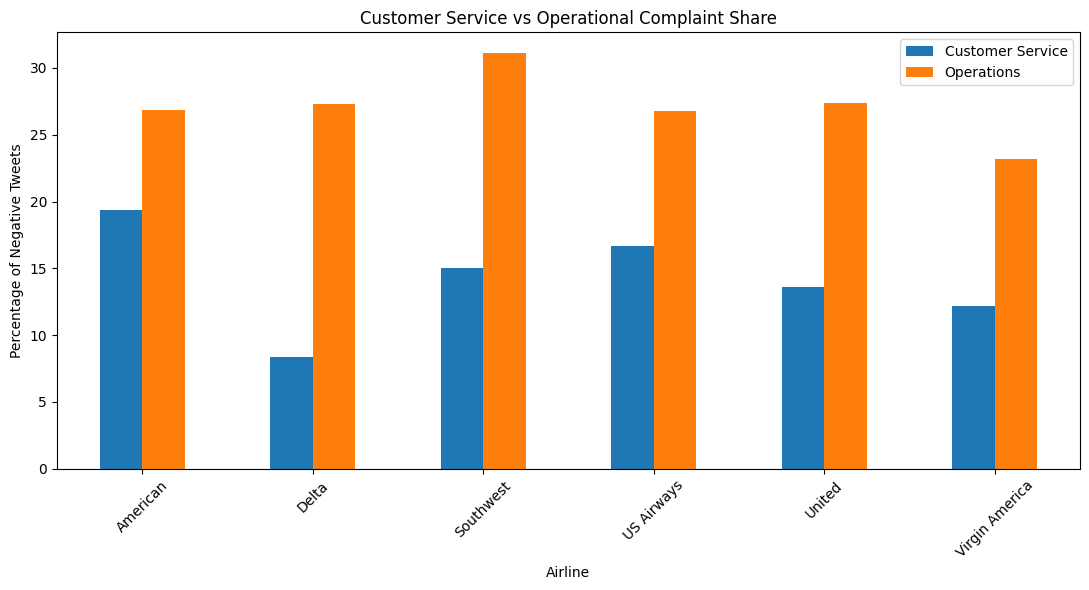

Highest customer service complaint share: American - 19.34 %
Highest operational complaint share: Southwest - 31.11 %


In [23]:
#partd
#q13
# Select negative tweets
negative = part_d[
    part_d['sentiment'] == 'negative'
].copy()

# Keywords for customer service complaints
service_keywords = [
    'customer service', 'customer support', 'rude',
    'agent', 'representative', 'staff', 'unhelpful',
    'no response', 'not answering', 'phone'
]

# Keywords for operational complaints
operations_keywords = [
    'delay', 'delayed', 'cancel', 'cancelled', 'canceled',
    'cancellation', 'baggage', 'luggage', 'lost bag',
    'missed connection', 'boarding', 'overbooked',
    'stranded', 'rescheduled', 'late flight'
]

def contains_keyword(text, keywords):
    text = text.lower()
    return any(keyword in text for keyword in keywords)

negative['customer_service'] = negative['tweet_text'].apply(
    lambda x: contains_keyword(x, service_keywords)
)

negative['operations'] = negative['tweet_text'].apply(
    lambda x: contains_keyword(x, operations_keywords)
)

# Count complaint types by airline
airline_complaints = negative.groupby('airline_name').agg(
    Total_Negative=('tweet_text', 'count'),
    Customer_Service=('customer_service', 'sum'),
    Operations=('operations', 'sum')
).reset_index()

# Calculate complaint shares
airline_complaints['Service_Share_%'] = (
    airline_complaints['Customer_Service'] /
    airline_complaints['Total_Negative'] * 100
).round(2)

airline_complaints['Operations_Share_%'] = (
    airline_complaints['Operations'] /
    airline_complaints['Total_Negative'] * 100
).round(2)

print("Complaint comparison across airlines:")
display(airline_complaints.sort_values(
    'Total_Negative', ascending=False
))

# Visual comparison
airline_complaints.plot(
    x='airline_name',
    y=['Service_Share_%', 'Operations_Share_%'],
    kind='bar',
    figsize=(11, 6)
)

plt.title('Customer Service vs Operational Complaint Share')
plt.xlabel('Airline')
plt.ylabel('Percentage of Negative Tweets')
plt.xticks(rotation=45)
plt.legend(['Customer Service', 'Operations'])
plt.tight_layout()
plt.show()

# Identify the airline with the highest share of each complaint type
service_airline = airline_complaints.loc[
    airline_complaints['Service_Share_%'].idxmax()
]

operations_airline = airline_complaints.loc[
    airline_complaints['Operations_Share_%'].idxmax()
]

print("Highest customer service complaint share:",
      service_airline['airline_name'],
      "-", service_airline['Service_Share_%'], "%")

print("Highest operational complaint share:",
      operations_airline['airline_name'],
      "-", operations_airline['Operations_Share_%'], "%")

Raw negative counts and negative shares:


,airline_name,Total_Tweets,Negative_Tweets,Negative_Share_%,Count_Rank,Share_Rank
4,United,3822,2633,68.89,1,3
3,US Airways,2913,2263,77.69,2,1
0,American,2759,1960,71.04,3,2
2,Southwest,2420,1186,49.01,4,4
1,Delta,2222,955,42.98,5,5
5,Virgin America,504,181,35.91,6,6



Example where raw count and share tell different stories:
Airline: American
Negative tweets: 1960
Total tweets: 2759
Negative share: 71.04 %
Rank by raw count: 3
Rank by negative share: 2


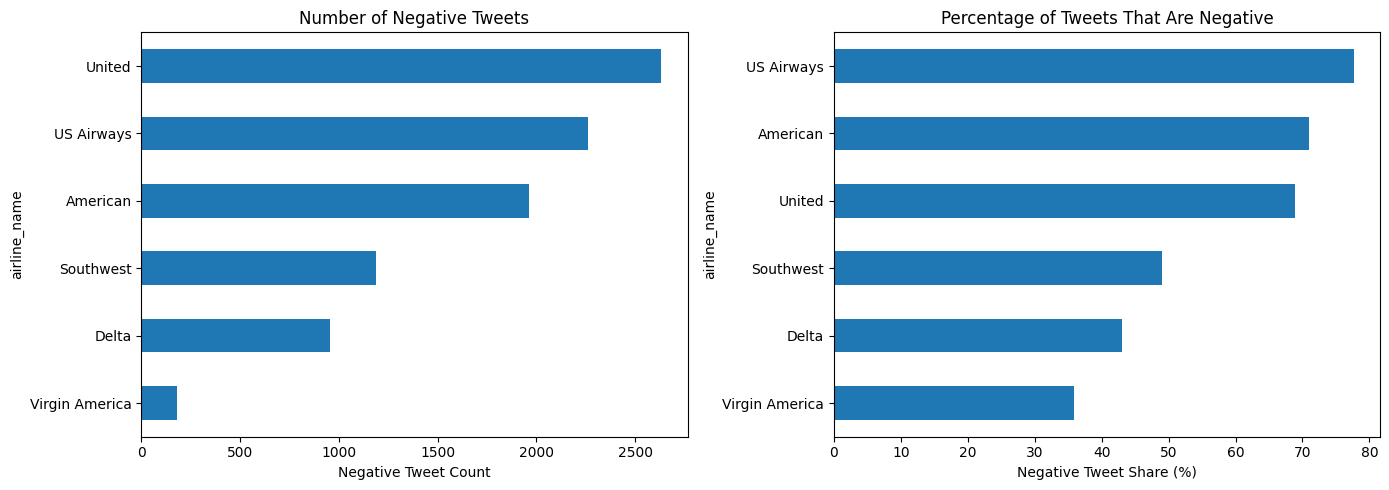

In [24]:
#q14
# Count total and negative tweets for each airline
airline_sentiment = part_d.groupby('airline_name').agg(
    Total_Tweets=('sentiment', 'count'),
    Negative_Tweets=('sentiment', lambda x: (x == 'negative').sum())
).reset_index()

# Calculate negative sentiment share
airline_sentiment['Negative_Share_%'] = (
    airline_sentiment['Negative_Tweets'] /
    airline_sentiment['Total_Tweets'] * 100
).round(2)

# Rank airlines using both measures
airline_sentiment['Count_Rank'] = (
    airline_sentiment['Negative_Tweets']
    .rank(ascending=False, method='min')
    .astype(int)
)

airline_sentiment['Share_Rank'] = (
    airline_sentiment['Negative_Share_%']
    .rank(ascending=False, method='min')
    .astype(int)
)

print("Raw negative counts and negative shares:")
display(airline_sentiment.sort_values(
    'Negative_Tweets', ascending=False
))

# Find an airline whose ranking differs
different_rank = airline_sentiment[
    airline_sentiment['Count_Rank'] != airline_sentiment['Share_Rank']
].copy()

if not different_rank.empty:
    example = different_rank.sort_values(
        'Count_Rank', ascending=False
    ).iloc[0]

    print("\nExample where raw count and share tell different stories:")
    print("Airline:", example['airline_name'])
    print("Negative tweets:", example['Negative_Tweets'])
    print("Total tweets:", example['Total_Tweets'])
    print("Negative share:", example['Negative_Share_%'], "%")
    print("Rank by raw count:", example['Count_Rank'])
    print("Rank by negative share:", example['Share_Rank'])
else:
    print("\nNo ranking differences were found.")

# Visual comparison of raw counts and shares
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

airline_sentiment.sort_values(
    'Negative_Tweets'
).plot(
    x='airline_name', y='Negative_Tweets',
    kind='barh', ax=axes[0], legend=False
)

axes[0].set_title('Number of Negative Tweets')
axes[0].set_xlabel('Negative Tweet Count')

airline_sentiment.sort_values(
    'Negative_Share_%'
).plot(
    x='airline_name', y='Negative_Share_%',
    kind='barh', ax=axes[1], legend=False
)

axes[1].set_title('Percentage of Tweets That Are Negative')
axes[1].set_xlabel('Negative Tweet Share (%)')

plt.tight_layout()
plt.show()

In [25]:
#q15
# Find a date/time column
date_candidates = [
    col for col in part_d.columns
    if any(word in col.lower() for word in ['date', 'created', 'time', 'timestamp'])
]

if not date_candidates:
    print("No date/time column was found. Time trends cannot be analyzed.")
    print("Available columns:", part_d.columns.tolist())

else:
    date_col = date_candidates[0]
    print("Date column used:", date_col)

    # Convert dates
    time_data = part_d.copy()
    time_data['tweet_date'] = pd.to_datetime(
        time_data[date_col],
        errors='coerce',
        utc=True
    )

    time_data = time_data.dropna(subset=['tweet_date'])

    if time_data.empty:
        print("No valid dates were found in the selected date column.")

    else:
        # Extract calendar date
        time_data['day'] = time_data['tweet_date'].dt.date

        # Calculate daily tweet counts and negative shares
        daily = time_data.groupby('day').agg(
            Total_Tweets=('sentiment', 'count'),
            Negative_Tweets=('sentiment', lambda x: (x == 'negative').sum())
        ).reset_index()

        daily['Negative_Share_%'] = (
            daily['Negative_Tweets'] /
            daily['Total_Tweets'] * 100
        )

        # Calculate 7-day rolling average
        daily['Rolling_Average'] = (
            daily['Negative_Share_%'].rolling(
                window=7, min_periods=1
            ).mean()
        )

        # Identify unusual spikes using mean + 2 standard deviations
        average = daily['Negative_Share_%'].mean()
        standard_deviation = daily['Negative_Share_%'].std()

        spike_limit = average + (2 * standard_deviation)

        daily['Possible_Spike'] = (
            daily['Negative_Share_%'] > spike_limit
        )

        print("Daily negative sentiment results:")
        display(daily.sort_values(
            'Negative_Share_%', ascending=False
        ).head(15))

        # Plot negative sentiment share over time
        plt.figure(figsize=(13, 6))

        plt.plot(
            daily['day'],
            daily['Negative_Share_%'],
            marker='o',
            label='Daily Negative Share'
        )

        plt.plot(
            daily['day'],
            daily['Rolling_Average'],
            linewidth=2,
            label='7-Day Rolling Average'
        )

        plt.axhline(
            spike_limit,
            linestyle='--',
            label='Possible Spike Threshold'
        )

        plt.title('Negative Sentiment Over Time')
        plt.xlabel('Date')
        plt.ylabel('Negative Tweets (%)')
        plt.xticks(rotation=45)
        plt.legend()
        plt.tight_layout()
        plt.show()

        # Display possible spikes
        spikes = daily[daily['Possible_Spike']]

        print("\nPossible negative sentiment spikes:")
        if len(spikes) > 0:
            display(spikes[['day', 'Total_Tweets',
                            'Negative_Tweets', 'Negative_Share_%']])
        else:
            print("No days exceeded the spike threshold.")

Date column used: airline_sentiment
No valid dates were found in the selected date column.


/tmp/ipykernel_2641/3859037196.py:18: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  time_data['tweet_date'] = pd.to_datetime(


Highest-priority negative tweets:


,tweet_text,airline_name,Priority_Score,Response_Priority,Priority_Reason,Retweets,Likes
10573,@USAirways trying to Cancelled Flight a flight...,US Airways,11,High,"Serious operational issue, Operational disrupt...",0,0
1656,@united so the last seg of my flight from Denv...,United,10,High,"Serious operational issue, Operational disrupt...",0,0
2010,@united Conference begins in 3 hours. Up all n...,United,10,High,"Serious operational issue, Operational disrupt...",0,0
4684,@SouthwestAir delayed twice now Cancelled Flig...,Southwest,10,High,"Serious operational issue, Operational disrupt...",0,0
5082,@southwestair I've been on hold for 2 hours to...,Southwest,10,High,"Serious operational issue, Operational disrupt...",0,0
6738,@SouthwestAir flight was Cancelled Flightled a...,Southwest,10,High,"Serious operational issue, Operational disrupt...",0,0
9897,@USAirways horrible cust service exp at DIA to...,US Airways,10,High,"Serious operational issue, Operational disrupt...",0,0
9936,@USAirways #695 might have been Cancelled Flig...,US Airways,10,High,"Serious operational issue, Operational disrupt...",0,0
10107,"@USAirways first flight Cancelled Flightled, c...",US Airways,10,High,"Serious operational issue, Operational disrupt...",0,0
10264,@USAirways just Cancelled Flighted my flight a...,US Airways,10,High,"Serious operational issue, Operational disrupt...",0,0



Response priority summary:


,Priority,Number of Tweets
0,Low,6083
1,Medium,1991
2,High,1104


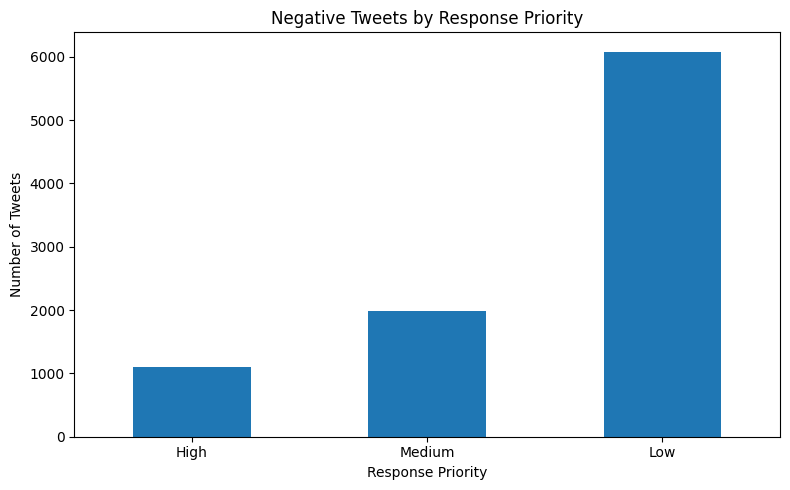

In [26]:
#q16
# Select negative tweets
priority_data = part_d[
    part_d['sentiment'] == 'negative'
].copy()

# Define urgency keywords
high_urgency_words = [
    'stranded', 'safety', 'unsafe', 'emergency',
    'missed connection', 'cancelled', 'canceled',
    'cancellation', 'lost baggage', 'lost luggage',
    'no hotel', 'no accommodation'
]

medium_urgency_words = [
    'delayed', 'delay', 'overbooked', 'rebook',
    'rescheduled', 'baggage', 'luggage',
    'refund', 'hours', 'waiting', 'stuck'
]

# Function to calculate urgency score
def calculate_priority(text):
    text = str(text).lower()

    score = 0
    reasons = []

    # Serious operational problems
    for word in high_urgency_words:
        if word in text:
            score += 5
            reasons.append('Serious operational issue')
            break

    # Other operational problems
    for word in medium_urgency_words:
        if word in text:
            score += 3
            reasons.append('Operational disruption')
            break

    # Customer needs immediate assistance
    urgent_phrases = [
        'please help', 'need help', 'right now',
        'still waiting', 'no response', 'urgent'
    ]

    for phrase in urgent_phrases:
        if phrase in text:
            score += 2
            reasons.append('Urgent assistance requested')
            break

    # Repeated punctuation or multiple question marks
    if text.count('?') >= 2 or text.count('!') >= 3:
        score += 1
        reasons.append('Strong expressed urgency')

    return score, ', '.join(reasons) if reasons else 'General complaint'

# Apply priority scoring
priority_results = priority_data['tweet_text'].apply(
    calculate_priority
)

priority_data['Priority_Score'] = priority_results.apply(lambda x: x[0])
priority_data['Priority_Reason'] = priority_results.apply(lambda x: x[1])

# Add engagement information if available
retweet_col = columns.get('retweet_count')
like_col = columns.get('like_count', columns.get('favorite_count'))

priority_data['Retweets'] = (
    pd.to_numeric(priority_data[retweet_col], errors='coerce').fillna(0)
    if retweet_col else 0
)

priority_data['Likes'] = (
    pd.to_numeric(priority_data[like_col], errors='coerce').fillna(0)
    if like_col else 0
)

# Add a small engagement bonus
priority_data['Priority_Score'] += (
    (priority_data['Retweets'] >= 10).astype(int) +
    (priority_data['Likes'] >= 10).astype(int)
)

# Assign response levels
def priority_level(score):
    if score >= 5:
        return 'High'
    elif score >= 3:
        return 'Medium'
    return 'Low'

priority_data['Response_Priority'] = (
    priority_data['Priority_Score'].apply(priority_level)
)

# Sort by priority, then engagement
priority_data = priority_data.sort_values(
    ['Priority_Score', 'Retweets', 'Likes'],
    ascending=False
)

print("Highest-priority negative tweets:")
display(priority_data[
    ['tweet_text', 'airline_name', 'Priority_Score',
     'Response_Priority', 'Priority_Reason', 'Retweets', 'Likes']
].head(20))

# Count tweets by response priority
priority_summary = priority_data['Response_Priority'].value_counts()

print("\nResponse priority summary:")
display(priority_summary.rename_axis(
    'Priority'
).reset_index(name='Number of Tweets'))

# Visualize priority groups
priority_order = ['High', 'Medium', 'Low']

priority_summary.reindex(priority_order, fill_value=0).plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Negative Tweets by Response Priority')
plt.xlabel('Response Priority')
plt.ylabel('Number of Tweets')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

part e
q17
17. The dataset could mislead the airline because:
- Twitter users are not representative of all passengers.
- Unhappy customers may be more likely to tweet than satisfied customers.
- Some passengers do not use Twitter or share their complaints online.
- Popular airlines may receive more tweets simply because they have more customers.
I trust the keyword-based complaint classification least because some tweets may be misunderstood or placed in the wrong category.

q18

18. Findings would likely change with data from today because airline services, customer expectations, technology, and social media language have changed since 2015. Common complaints, sentiment words, and airline rankings may be different. The overall problem of customer dissatisfaction would probably remain, but the specific issues and their frequency could change.


19. I would not completely replace the manual team. The automated tool can analyse large numbers of tweets quickly and identify common complaints. However, Part C showed that it can struggle with sarcasm, negation, and mixed feelings. I recommend using automation for initial analysis and allowing humans to review unclear or important tweets.



Part F: Additional Insights
Insight 1: Customer service is an important source of complaints.
- Observation: Many negative tweets appear to focus on poor customer service.
- Evidence: The customer-service complaint count and percentage in Part D, Question 13.
- Why it matters: Poor service can reduce customer satisfaction and damage the airline's reputation.
- Recommended action: Provide better staff training and improve customer support response times.
- Confidence and limits: Medium confidence because complaints were identified using keywords, which may sometimes misclassify tweets.
Insight 2: Some airlines receive a higher proportion of negative feedback.
- Observation: Some airlines have a higher negative-tweet percentage than others.
- Evidence: The negative percentage comparison chart in Part D, Question 14.
- Why it matters: Airlines with higher negative percentages may have more serious customer satisfaction problems.
- Recommended action: Investigate the reasons for dissatisfaction and improve the weakest service areas.
- Confidence and limits: Medium confidence because Twitter users do not represent all passengers.
Insight 3: Negative tweets can increase on particular days.
- Observation: The number or percentage of negative tweets may rise on certain days.
- Evidence: The daily negative-tweet trend chart in Part D, Question 15.
- Why it matters: Sudden increases may indicate delays, cancellations, or other service problems.
- Recommended action: Monitor complaints daily and investigate unusual increases quickly.
- Confidence and limits: Medium confidence because a spike does not prove its cause, and the dataset covers only a short period.
Insight 4: Urgent complaints should receive priority.
- Observation: Some negative tweets describe urgent problems, such as cancellations, missed connections, or lost baggage.
- Evidence: The high-priority tweet counts and examples from Part D, Question 16.
- Why it matters: Delayed responses to urgent problems can make passengers more frustrated.
- Recommended action: Use automated tools to flag urgent complaints for quick human review.
- Confidence and limits: Medium confidence because the priority system uses keywords and may incorrectly classify some tweets.